In [1]:
import json
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import ConfusionMatrixDisplay

tf.keras.utils.set_random_seed(42)

In [2]:
with open("data/logic_gates.json") as f:
    data = json.load(f)

labels = {"AND": 0, "OR": 1, "XOR": 2}

x, y = [], []

for sample in data:
    w1 = sample["weights"]["w1"]
    w2 = sample["weights"]["w2"]
    b1 = sample["biases"]["b1"]
    b2 = sample["biases"]["b2"]

    tokens = [
        [w1[0][0], w1[0][1], b1[0], 0],
        [w1[1][0], w1[1][1], b1[1], 0],
        [w2[0][0], w2[0][1], b2[0], 1]
    ]

    x.append(tokens)
    y.append(labels[sample["gate"]])

x = np.array(x, dtype=np.float32)
y = np.array(y, dtype=np.int32)

print("x:", x.shape)
print("y:", y.shape)

x: (300, 3, 4)
y: (300,)


In [3]:
indices = np.random.permutation(len(x))
split = int(0.8 * len(x))

train_idx, val_idx = indices[:split], indices[split:]

x_train, x_val = x[train_idx], x[val_idx]
y_train, y_val = y[train_idx], y[val_idx]

In [4]:
def transformer_block(x):
    attention = layers.MultiHeadAttention(
        num_heads=2,
        key_dim=8
    )(x, x)

    x = layers.LayerNormalization()(x + attention)

    ff = layers.Dense(32, activation="gelu")(x)
    ff = layers.Dense(16)(ff)

    return layers.LayerNormalization()(x + ff)

In [5]:
inputs = keras.Input(shape=(3, 4))

x = layers.Dense(16)(inputs)
x = transformer_block(x)
x = layers.GlobalAveragePooling1D()(x)

outputs = layers.Dense(3, activation="softmax")(x)

model = keras.Model(inputs, outputs)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 3, 4)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 3, 16)     │         80 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 3, 16)     │      1,088 │ dense[0][0],      │
│ (MultiHeadAttentio… │                   │            │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 3, 16)     │          0 │ dense[0][0],      │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 3, 16)     │         32 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 3, 32)     │        544 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 3, 16)     │        528 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 3, 16)     │          0 │ layer_normalizat… │
│                     │                   │            │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 3, 16)     │         32 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 16)        │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 3)         │         51 │ global_average_p… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,355 (9.20 KB)

 Trainable params: 2,355 (9.20 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=50,
    batch_size=4,
    verbose=1
)

Epoch 1/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4625 - loss: 1.1251 - val_accuracy: 0.4000 - val_loss: 1.1313
Epoch 2/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 990us/step - accuracy: 0.5833 - loss: 0.9730 - val_accuracy: 0.5333 - val_loss: 0.9727
Epoch 3/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 948us/step - accuracy: 0.6625 - loss: 0.8597 - val_accuracy: 0.6833 - val_loss: 0.8339
Epoch 4/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 952us/step - accuracy: 0.7333 - loss: 0.7424 - val_accuracy: 0.7833 - val_loss: 0.6752
Epoch 5/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 952us/step - accuracy: 0.8333 - loss: 0.5726 - val_accuracy: 0.8833 - val_loss: 0.4881
Epoch 6/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8875 - loss: 0.3973 - val_accuracy: 0.8500 - val_loss: 0.3671
Epoch 7/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9375 - loss: 0.2614 - val_accuracy: 0.9333 - val_loss: 0.2119
Epoch 8/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9708 - loss: 0.1651 - val_accuracy: 1.0000 - v

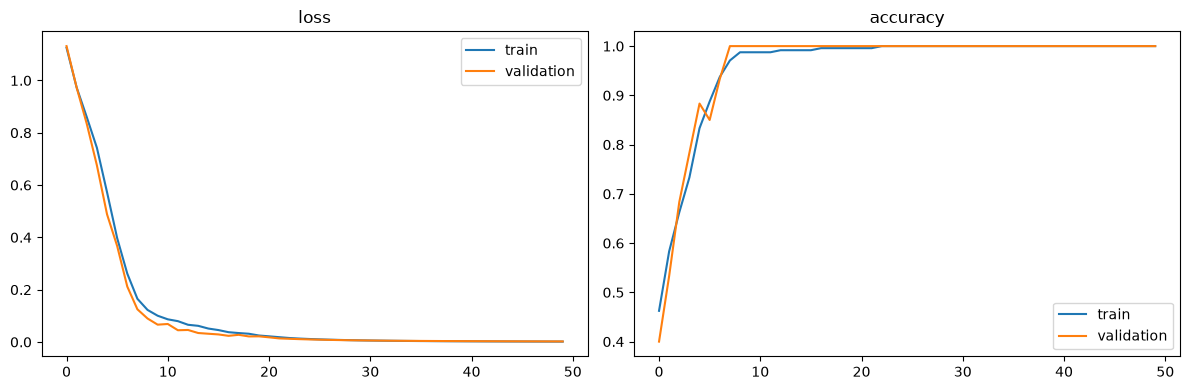

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(history.history["loss"], label="train")
ax[0].plot(history.history["val_loss"], label="validation")
ax[0].set_title("loss")
ax[0].legend()

ax[1].plot(history.history["accuracy"], label="train")
ax[1].plot(history.history["val_accuracy"], label="validation")
ax[1].set_title("accuracy")
ax[1].legend()

plt.tight_layout()
plt.show()

In [8]:
loss, accuracy = model.evaluate(x_val, y_val)

print("val loss:", loss)
print("val accuracy:", accuracy)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 1.0000 - loss: 0.0021  
val loss: 0.0021321445237845182
val accuracy: 1.0


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step


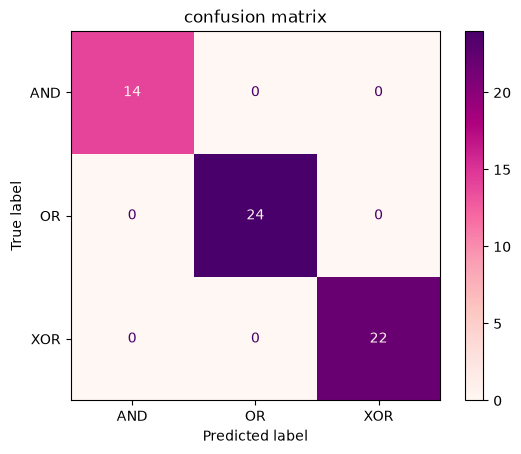

In [9]:
predictions = np.argmax(model.predict(x_val), axis=1)

ConfusionMatrixDisplay.from_predictions(
    y_val,
    predictions,
    display_labels=["AND", "OR", "XOR"],
    cmap='RdPu'
)

plt.title("confusion matrix")
plt.show()